#  Concrete Strength — Prediction & Classification

**Part 1 (Regression):** predict the compressive strength of concrete (a number, in MPa) from its ingredients and age.

**Part 2 (Classification):** decide if a concrete mix is **Strong** or **Weak** (a yes/no answer).

| Column | Unit | Meaning |
|---|---|---|
| Cement, Blast Furnace Slag, Fly Ash | kg/m³ | Binder materials |
| Water, Superplasticizer | kg/m³ | Water and water-reducing additive |
| Coarse / Fine Aggregate | kg/m³ | Gravel and sand |
| Age | days | Curing time before the test |
| **Strength (target)** | MPa | Compressive strength |

### Notebook Roadmap
1. Import Libraries
2. Load Data
3. Data Cleaning
4. Exploratory Data Analysis (EDA)
5. Feature Engineering
6. Train / Test Split
7. **Part 1 — Regression Models** (one model per cell)
8. **Part 2 — Classification Models** (one model per cell)
9. Save the Model & Predict a New Mix
10. Final Summary

## 1. Import Libraries
Everything we need is imported here **once**.

In [1]:
# Data handling
import pandas as pd
import numpy as np

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Saving the model
import joblib

# Regression models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    ExtraTreesRegressor,
    RandomForestRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    VotingRegressor
)
from sklearn.neural_network import MLPRegressor

# Classification models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

# Tools
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split, KFold, StratifiedKFold,
    GridSearchCV, cross_val_score, cross_val_predict
)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    r2_score, mean_squared_error, mean_absolute_error,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix
)

# Make plots look nicer
sns.set_style("whitegrid")

## 2. Load Data
Put `Concrete_Data.xls` (or `Concrete_Data.csv`) in the same folder as this notebook.

In [2]:
try:
    df = pd.read_excel('Concrete_Data.xls')
except Exception:
    df = pd.read_csv('Concrete_Data.csv')

df.head()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


The original column names are very long, so we give them short and simple names.

In [3]:
df.columns = [
    "Cement",
    "Blast_Furnace_Slag",
    "Fly_Ash",
    "Water",
    "Superplasticizer",
    "Coarse_Aggregate",
    "Fine_Aggregate",
    "Age",
    "Strength"      # <-- the TARGET (what we want to predict)
]

df.columns

Index(['Cement', 'Blast_Furnace_Slag', 'Fly_Ash', 'Water', 'Superplasticizer',
       'Coarse_Aggregate', 'Fine_Aggregate', 'Age', 'Strength'],
      dtype='object')

## 3. Data Cleaning
We check missing values and duplicated rows.

In [4]:
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicated rows:", df.duplicated().sum())

Dataset shape: (1030, 9)
Missing values: 0
Duplicated rows: 25


Duplicated rows are removed **before** splitting, so the same mix can never appear in both the training set and the test set.

In [5]:
df = df.drop_duplicates().reset_index(drop=True)

print("Duplicated rows after cleaning:", df.duplicated().sum())
print("Dataset shape:", df.shape)

Duplicated rows after cleaning: 0
Dataset shape: (1005, 9)


## 4. Exploratory Data Analysis (EDA)

In [6]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Cement,1005.0,278.63,104.35,102.00,190.68,265.0,349.00,540.0
Blast_Furnace_Slag,1005.0,72.04,86.17,0.00,0.00,20.0,142.50,359.4
Fly_Ash,1005.0,55.54,64.21,0.00,0.00,0.0,118.27,200.1
Water,1005.0,182.07,21.34,121.75,166.61,185.7,192.94,247.0
Superplasticizer,1005.0,6.03,5.92,0.00,0.00,6.1,10.00,32.2
Coarse_Aggregate,1005.0,974.38,77.58,801.00,932.00,968.0,1031.00,1145.0
Fine_Aggregate,1005.0,772.69,80.34,594.00,724.30,780.0,822.20,992.6
Age,1005.0,45.86,63.73,1.00,7.00,28.0,56.00,365.0
Strength,1005.0,35.25,16.28,2.33,23.52,33.8,44.87,82.6


### 4.1 Target Distribution

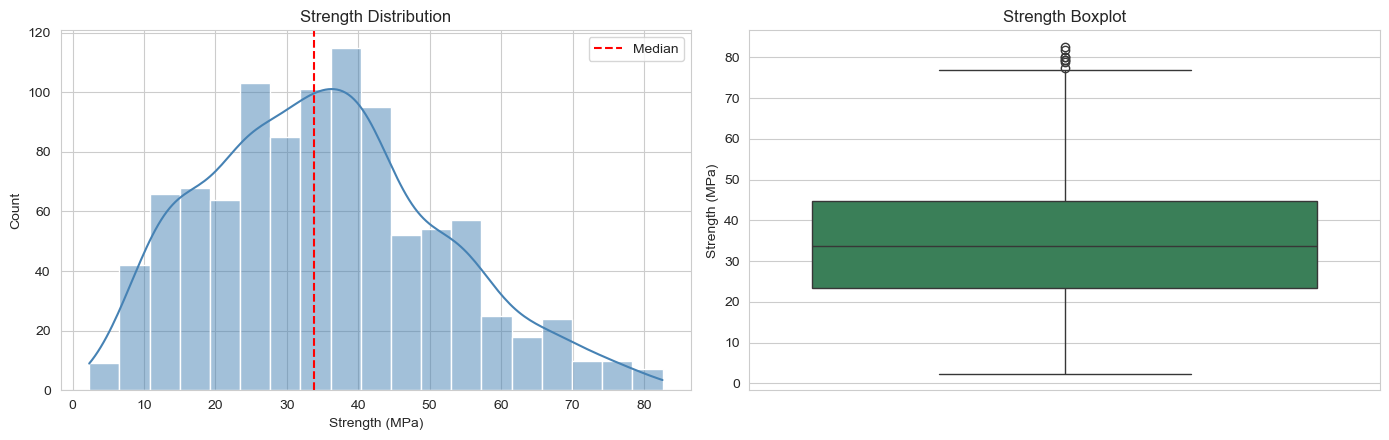

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(data=df, x="Strength", kde=True, color="steelblue", ax=axes[0])
axes[0].axvline(df["Strength"].median(), color="red", linestyle="--", label="Median")
axes[0].set_title("Strength Distribution")
axes[0].set_xlabel("Strength (MPa)")
axes[0].legend()

sns.boxplot(y=df["Strength"], color="seagreen", ax=axes[1])
axes[1].set_title("Strength Boxplot")
axes[1].set_ylabel("Strength (MPa)")

plt.tight_layout()
plt.show()

### 4.2 Distribution of Each Input Feature

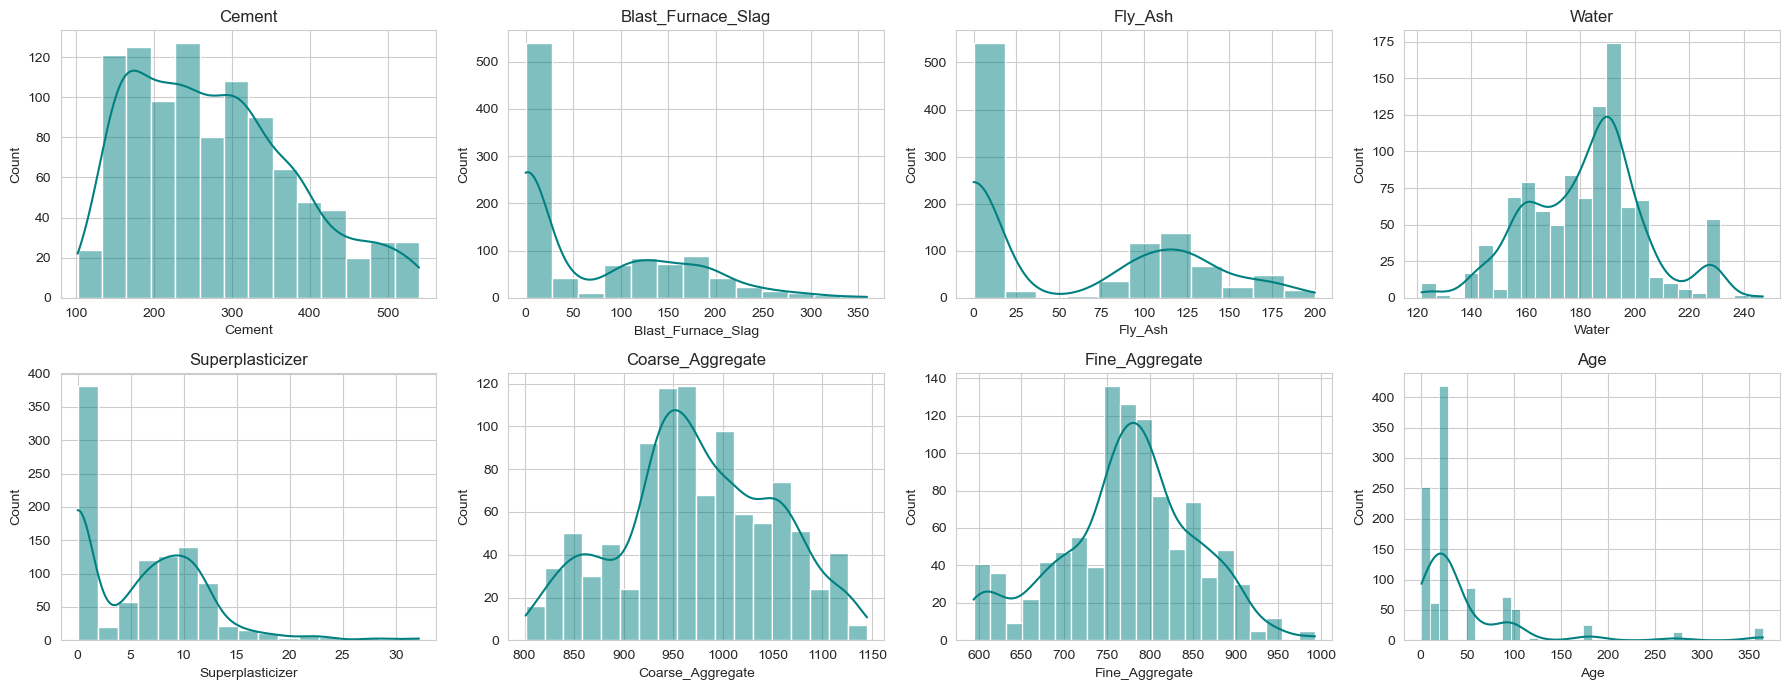

In [8]:
input_columns = [
    "Cement", "Blast_Furnace_Slag", "Fly_Ash", "Water",
    "Superplasticizer", "Coarse_Aggregate", "Fine_Aggregate", "Age"
]

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
axes = axes.ravel()

for ax, column in zip(axes, input_columns):
    sns.histplot(data=df, x=column, kde=True, color="teal", ax=ax)
    ax.set_title(column)

plt.tight_layout()
plt.show()

### 4.3 Each Feature vs Strength
`r` is the correlation: close to **+1** means "when this goes up, strength goes up", close to **-1** means the opposite.

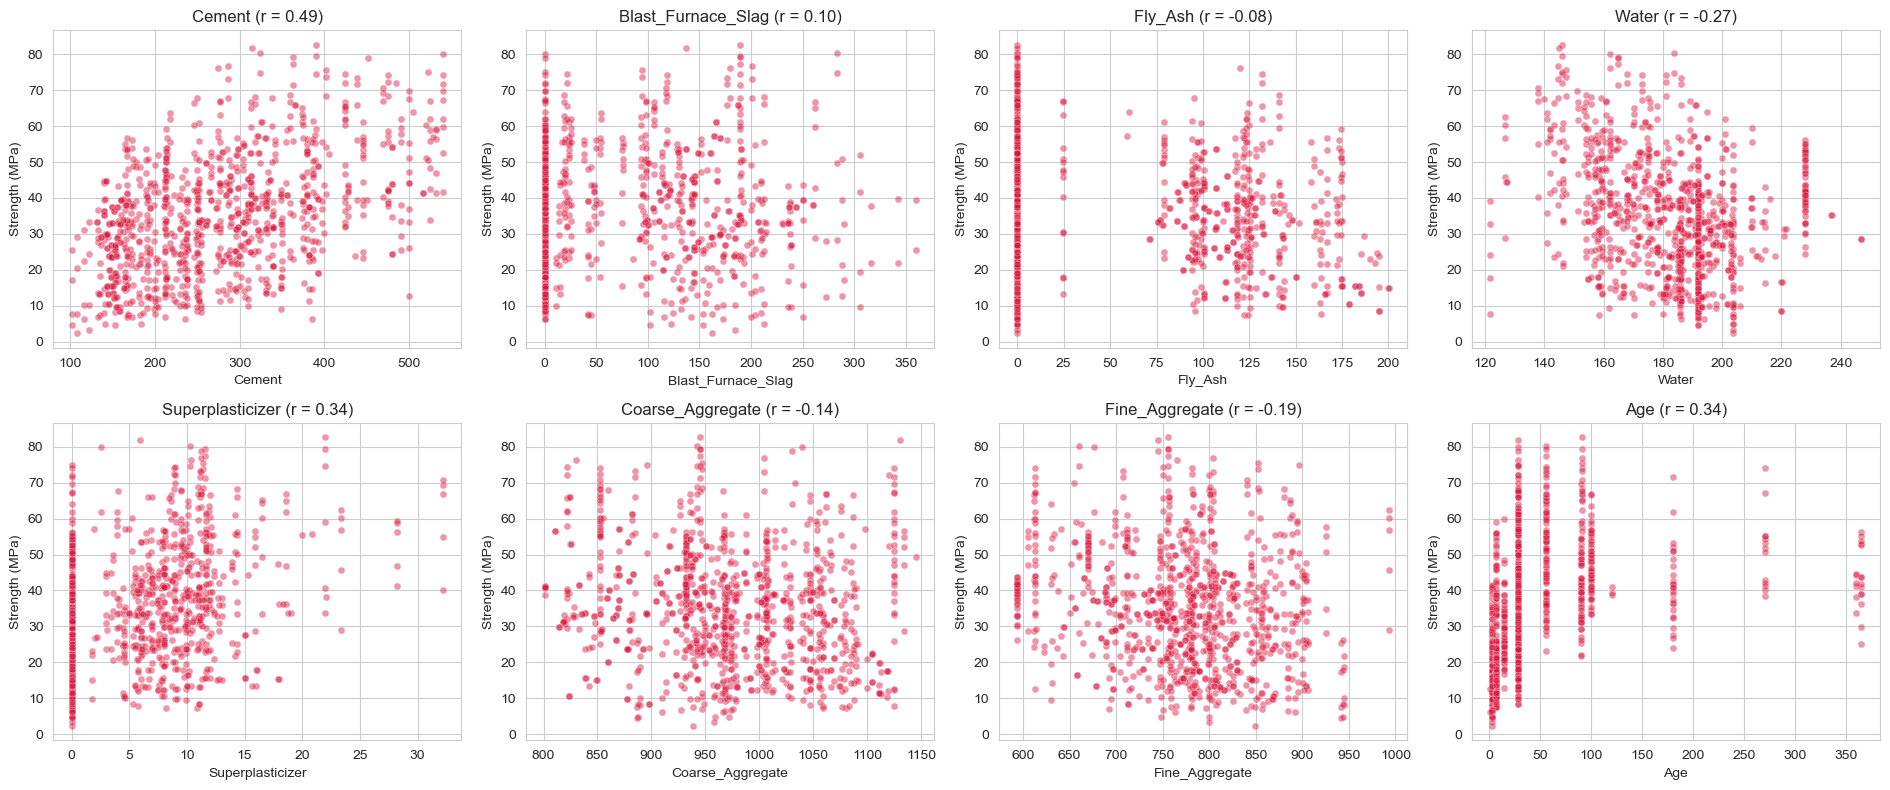

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(19, 8))
axes = axes.ravel()

for ax, column in zip(axes, input_columns):
    r = df[column].corr(df["Strength"])
    sns.scatterplot(data=df, x=column, y="Strength", alpha=0.45, s=25, color="crimson", ax=ax)
    ax.set_title(f"{column} (r = {r:.2f})")
    ax.set_ylabel("Strength (MPa)")

plt.tight_layout()
plt.show()

### 4.4 Correlation Heatmap

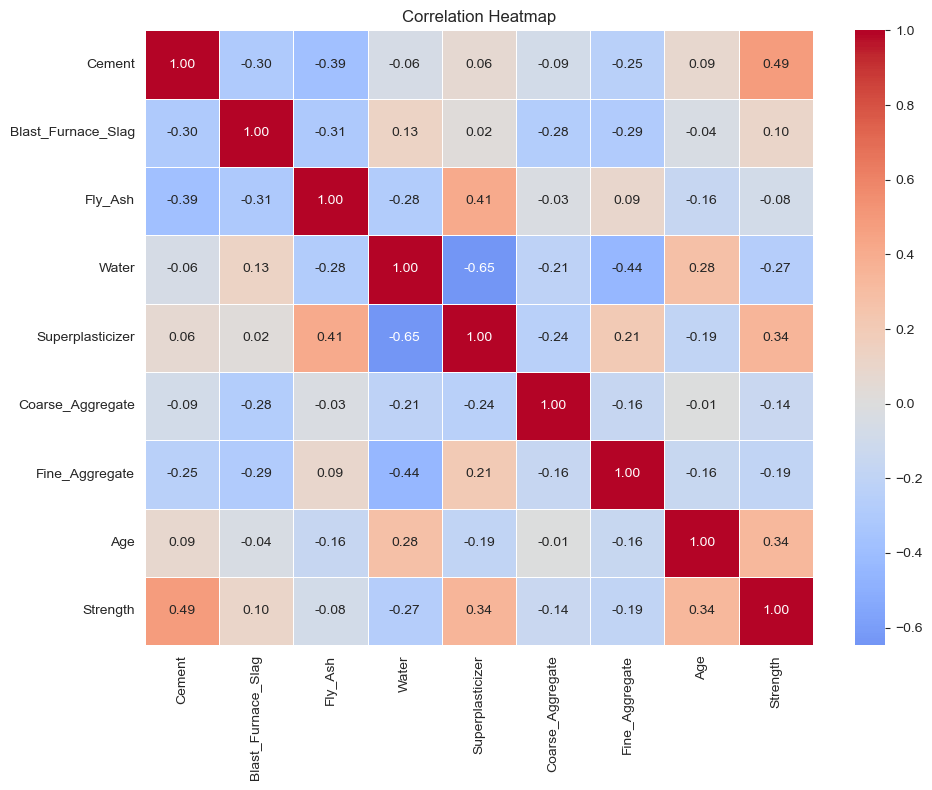

In [10]:
plt.figure(figsize=(10, 8))

sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 5. Feature Engineering
In concrete science, strength depends on **ratios** (like water compared to binder) and grows **non-linearly** with age.
So we create new columns from the existing ones.

All steps are inside **one function**, so we can reuse it when predicting a new mix.

In [11]:
def add_features(data):
    """Takes a DataFrame with the 8 original input columns and adds new features."""
    data = data.copy()

    # Water compared to cement
    data["Water_Cement_Ratio"] = data["Water"] / data["Cement"]

    # Total binder = cement + slag + fly ash
    data["Binder"] = data["Cement"] + data["Blast_Furnace_Slag"] + data["Fly_Ash"]

    # Water compared to total binder
    data["Water_Binder_Ratio"] = data["Water"] / data["Binder"]

    # Strength grows fast at early ages, then slows down -> use log of age
    data["Log_Age"] = np.log1p(data["Age"])

    return data

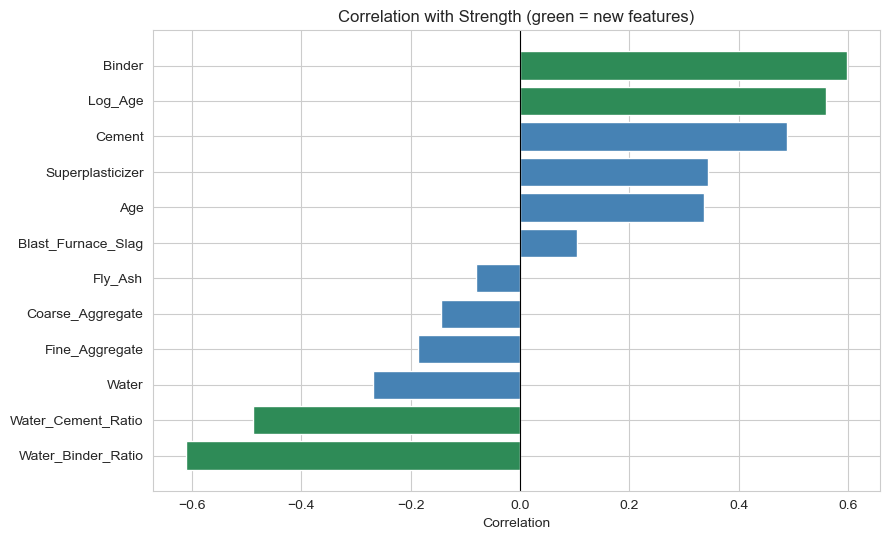

In [12]:
df = add_features(df)

new_features = ["Water_Cement_Ratio", "Binder", "Water_Binder_Ratio", "Log_Age"]

# Correlation of every feature with Strength (green = new features)
correlation = df.corr()["Strength"].drop("Strength").sort_values()
bar_colors = ["seagreen" if name in new_features else "steelblue" for name in correlation.index]

plt.figure(figsize=(9, 5.5))
plt.barh(correlation.index, correlation.values, color=bar_colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation with Strength (green = new features)")
plt.xlabel("Correlation")
plt.tight_layout()
plt.show()

## 6. Train / Test Split
- **80%** for training, **20%** kept hidden for the final test.
- We split in a *stratified* way: the data is divided into 5 strength groups (low → high), and each group is split 80/20.
  This makes sure the training and test sets both cover the **full range** of strengths.

In [13]:
X = df.drop(columns=["Strength"])   # inputs
y = df["Strength"]                  # target

strength_groups = pd.qcut(y, q=5, labels=False)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=strength_groups
)

print("Train:", X_train.shape)
print("Test: ", X_test.shape)

Train: (804, 12)
Test:  (201, 12)


In [14]:
# 5-Fold cross-validation (used to tune and compare the models)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Part 1 — Regression (Predict the Strength in MPa)

## 7. Regression Models
### Helper function
One function does the same job for every model:
1. Build a pipeline (scaling only if the model needs it).
2. Find the best settings with **GridSearchCV** + 5-fold cross-validation.
3. Evaluate on the test set.
4. Save the results for the comparison table.

Then every model gets **its own cell**.

In [15]:
reg_results = []          # scores of every model
trained_models = {}       # best trained version of every model


def train_regressor(name, model, param_grid, use_scaler=False):
    """Tune one regression model, test it, and save its results."""

    # Step 1: build the pipeline
    steps = []
    if use_scaler:
        steps.append(("scaler", StandardScaler()))
    steps.append(("model", model))
    pipeline = Pipeline(steps)

    # Step 2: search for the best settings
    grid_search = GridSearchCV(pipeline, param_grid, cv=kf, scoring="r2", n_jobs=-1)
    grid_search.fit(X_train, y_train)
    best_pipeline = grid_search.best_estimator_

    # Step 3: evaluate on train and test
    train_pred = best_pipeline.predict(X_train)
    test_pred = best_pipeline.predict(X_test)

    # Step 4: save the results
    reg_results.append({
        "Model": name,
        "CV R2": grid_search.best_score_,
        "Train R2": r2_score(y_train, train_pred),
        "Test R2": r2_score(y_test, test_pred),
        "Test RMSE (MPa)": np.sqrt(mean_squared_error(y_test, test_pred)),
        "Test MAE (MPa)": mean_absolute_error(y_test, test_pred),
    })
    trained_models[name] = best_pipeline

    print(name)
    print(f"  CV R2 : {grid_search.best_score_:.4f}")
    print(f"  Test R2 : {r2_score(y_test, test_pred):.4f}")
    print(f"  Test RMSE : {np.sqrt(mean_squared_error(y_test, test_pred)):.3f} MPa")
    print(f"  Best settings: {grid_search.best_params_}")

### 7.1 Linear Regression (Baseline)
The simplest model. Every other model should beat it.

In [16]:
train_regressor(
    name="Linear Regression",
    model=LinearRegression(),
    param_grid={},              # nothing to tune
    use_scaler=True
)

Linear Regression
  CV R2 : 0.8177
  Test R2 : 0.8099
  Test RMSE : 7.383 MPa
  Best settings: {}


### 7.2 Extra Trees
Many random decision trees. The final answer is the **average** of all trees.

In [17]:
train_regressor(
    name="Extra Trees",
    model=ExtraTreesRegressor(random_state=42),
    param_grid={
        "model__n_estimators": [300, 600],
        "model__max_depth": [None, 20],
        "model__min_samples_split": [2, 4]
    }
)

Extra Trees
  CV R2 : 0.8996
  Test R2 : 0.9229
  Test RMSE : 4.700 MPa
  Best settings: {'model__max_depth': 20, 'model__min_samples_split': 4, 'model__n_estimators': 600}


### 7.3 Random Forest
Similar to Extra Trees, but each tree is trained on a random sample of the data.

In [18]:
train_regressor(
    name="Random Forest",
    model=RandomForestRegressor(random_state=42),
    param_grid={
        "model__n_estimators": [300, 500],
        "model__max_features": [0.6, 1.0],
        "model__min_samples_leaf": [1, 2]
    }
)

Random Forest
  CV R2 : 0.8995
  Test R2 : 0.9203
  Test RMSE : 4.780 MPa
  Best settings: {'model__max_features': 0.6, 'model__min_samples_leaf': 1, 'model__n_estimators': 500}


### 7.4 Gradient Boosting
Trees are built **one after another**, and each new tree fixes the mistakes of the previous ones. Usually the strongest model on this kind of data.

In [19]:
train_regressor(
    name="Gradient Boosting",
    model=GradientBoostingRegressor(random_state=42),
    param_grid={
        "model__n_estimators": [400, 700],
        "model__learning_rate": [0.03, 0.05, 0.07],
        "model__max_depth": [3, 4, 5],
        "model__subsample": [0.7, 0.8]      # each tree sees only part of the rows -> less overfitting
    }
)

Gradient Boosting
  CV R2 : 0.9267
  Test R2 : 0.9506
  Test RMSE : 3.764 MPa
  Best settings: {'model__learning_rate': 0.03, 'model__max_depth': 4, 'model__n_estimators': 700, 'model__subsample': 0.7}


### 7.5 Hist Gradient Boosting
A faster, modern version of Gradient Boosting.

In [20]:
train_regressor(
    name="Hist Gradient Boosting",
    model=HistGradientBoostingRegressor(random_state=42),
    param_grid={
        "model__max_iter": [300, 600],
        "model__learning_rate": [0.03, 0.06],
        "model__max_leaf_nodes": [15, 31],
        "model__l2_regularization": [0.0, 1.0]
    }
)

C:\Users\abq12\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\abq12\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\abq12\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\abq12\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

Hist Gradient Boosting
  CV R2 : 0.9241
  Test R2 : 0.9429
  Test RMSE : 4.045 MPa
  Best settings: {'model__l2_regularization': 0.0, 'model__learning_rate': 0.06, 'model__max_iter': 600, 'model__max_leaf_nodes': 15}


### 7.6 Neural Network (MLP)
A small neural network. It **needs scaling**, so we turn the scaler on.

In [21]:
train_regressor(
    name="Neural Network (MLP)",
    model=MLPRegressor(max_iter=3000, early_stopping=True, random_state=42),
    param_grid={
        "model__hidden_layer_sizes": [(128, 64), (256, 128)],
        "model__alpha": [0.001, 0.01]
    },
    use_scaler=True
)

Neural Network (MLP)
  CV R2 : 0.8980
  Test R2 : 0.8905
  Test RMSE : 5.603 MPa
  Best settings: {'model__alpha': 0.001, 'model__hidden_layer_sizes': (256, 128)}


### 7.7 Voting Ensemble
We take the **3 best models** (by cross-validation) and average their predictions.
Models make different mistakes, so the average is often better than any single model.

In [22]:
# Find the 3 models with the best CV score
top3_names = (
    pd.DataFrame(reg_results)
    .sort_values(by="CV R2", ascending=False)["Model"]
    .head(3)
    .tolist()
)
print("Ensemble members:", top3_names)

# Put their (already tuned) pipelines in a list
members = []
for model_name in top3_names:
    members.append((model_name, trained_models[model_name]))

train_regressor(
    name="Voting Ensemble",
    model=VotingRegressor(members),
    param_grid={}               # nothing to tune, we reuse the best settings found above
)

Ensemble members: ['Gradient Boosting', 'Hist Gradient Boosting', 'Extra Trees']
Voting Ensemble
  CV R2 : 0.9253
  Test R2 : 0.9450
  Test RMSE : 3.971 MPa
  Best settings: {}


## 7.8 Compare All Regression Models
Models are ranked by **CV R²** (not by the test score), so the test set stays an honest final check.

`Overfit Gap` = Train R² − CV R². A big gap means the model memorized the training data.

In [23]:
reg_table = pd.DataFrame(reg_results).sort_values(by="CV R2", ascending=False).reset_index(drop=True)
reg_table["Overfit Gap"] = reg_table["Train R2"] - reg_table["CV R2"]

reg_table.round(4)

,Model,CV R2,Train R2,Test R2,Test RMSE (MPa),Test MAE (MPa),Overfit Gap
0,Gradient Boosting,0.9267,0.9890,0.9506,3.7637,2.5664,0.0623
1,Voting Ensemble,0.9253,0.9925,0.9450,3.9707,2.6289,0.0672
2,Hist Gradient Boosting,0.9241,0.9909,0.9429,4.0454,2.6783,0.0668
3,Extra Trees,0.8996,0.9928,0.9229,4.7000,3.1482,0.0932
4,Random Forest,0.8995,0.9865,0.9203,4.7804,3.4520,0.0870
5,Neural Network (MLP),0.8980,0.9441,0.8905,5.6032,4.0214,0.0461
6,Linear Regression,0.8177,0.8279,0.8099,7.3826,5.8968,0.0102


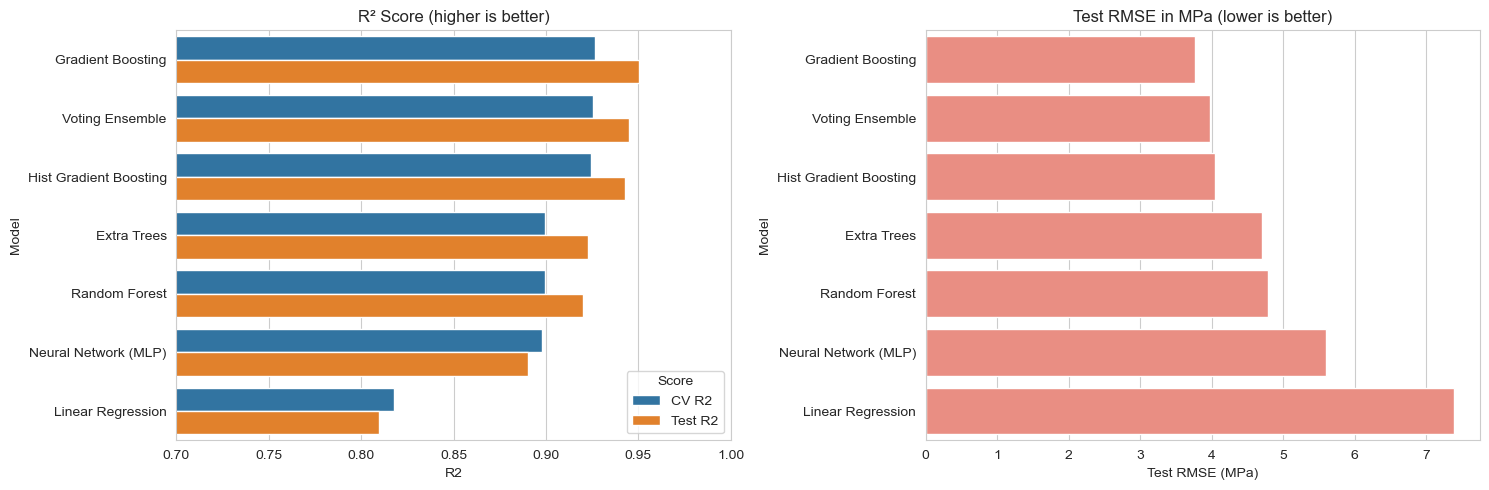

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# R2 comparison
plot_data = reg_table.melt(id_vars="Model", value_vars=["CV R2", "Test R2"], var_name="Score", value_name="R2")
sns.barplot(data=plot_data, y="Model", x="R2", hue="Score", ax=axes[0])
axes[0].set_title("R² Score (higher is better)")
axes[0].set_xlim(0.7, 1.0)

# Error comparison
sns.barplot(data=reg_table, y="Model", x="Test RMSE (MPa)", color="salmon", ax=axes[1])
axes[1].set_title("Test RMSE in MPa (lower is better)")

plt.tight_layout()
plt.show()

In [47]:
best_regressor_name = reg_table.loc[0, "Model"]
best_regressor = trained_models[best_regressor_name]

print(" Best regression model:", best_regressor_name)

 Best regression model: Gradient Boosting


### 7.9 Best Model — Diagnostics
- **Actual vs Predicted:** points close to the red line = good predictions.
- **Residuals** (`actual − predicted`): should be centered around zero with no clear pattern.

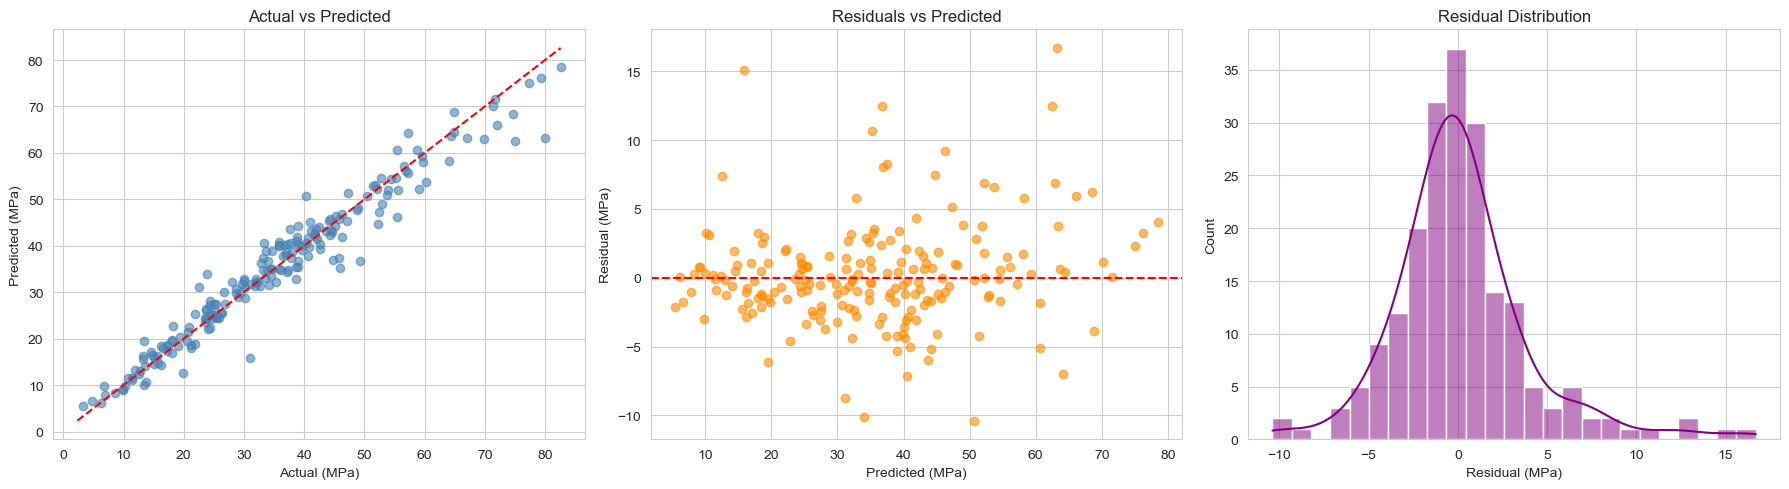

In [26]:
test_pred = best_regressor.predict(X_test)
residuals = y_test - test_pred

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) Actual vs Predicted
axes[0].scatter(y_test, test_pred, alpha=0.6, color="steelblue")
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], color="red", linestyle="--")
axes[0].set_title("Actual vs Predicted")
axes[0].set_xlabel("Actual (MPa)")
axes[0].set_ylabel("Predicted (MPa)")

# 2) Residuals vs Predicted
axes[1].scatter(test_pred, residuals, alpha=0.6, color="darkorange")
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residuals vs Predicted")
axes[1].set_xlabel("Predicted (MPa)")
axes[1].set_ylabel("Residual (MPa)")

# 3) Residual distribution
sns.histplot(residuals, kde=True, color="purple", ax=axes[2])
axes[2].set_title("Residual Distribution")
axes[2].set_xlabel("Residual (MPa)")

plt.tight_layout()
plt.show()

### 7.10 Feature Importance
We shuffle one feature at a time. The bigger the drop in R², the more important the feature.

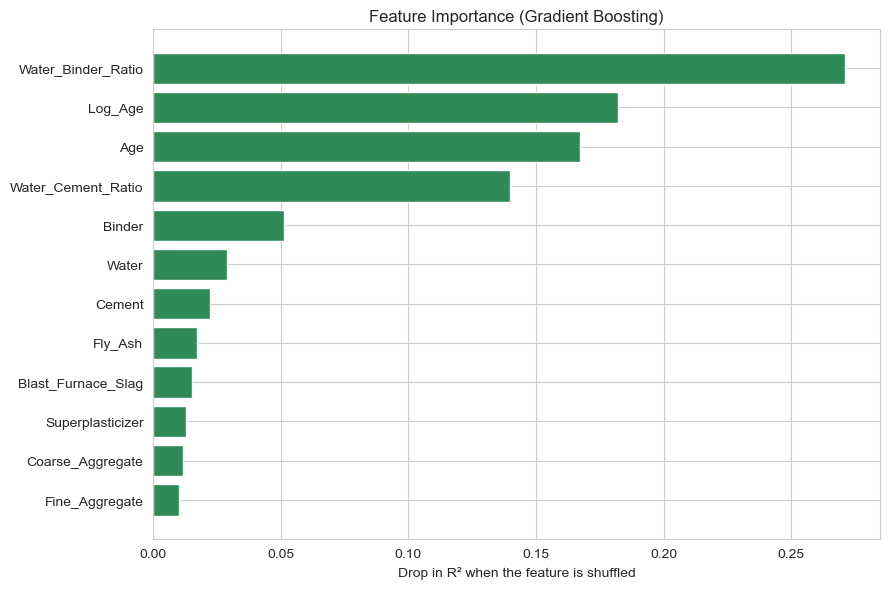

Top 3 features: ['Water_Binder_Ratio', 'Log_Age', 'Age']


In [27]:
importance = permutation_importance(
    best_regressor, X_test, y_test,
    n_repeats=10, random_state=42, scoring="r2"
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean
}).sort_values(by="Importance", ascending=True)

plt.figure(figsize=(9, 6))
plt.barh(importance_df["Feature"], importance_df["Importance"], color="seagreen")
plt.title(f"Feature Importance ({best_regressor_name})")
plt.xlabel("Drop in R² when the feature is shuffled")
plt.tight_layout()
plt.show()

top_features = importance_df["Feature"].tail(3).tolist()[::-1]
print("Top 3 features:", top_features)

# Part 2 — Classification (Strong or Weak?)

## 8. Classification Models
A mix is **Strong** if its strength is **at or above the median strength of the training set** (the `cutoff`). Otherwise it is **Weak**.
Using the median keeps the two classes balanced (about 50% / 50%).

In [28]:
cutoff = y_train.median()

y_train_c = (y_train >= cutoff).astype(int)    # 1 = Strong, 0 = Weak
y_test_c = (y_test >= cutoff).astype(int)

print(f"Cutoff = {cutoff:.2f} MPa")

balance = pd.DataFrame({
    "Train": y_train_c.value_counts(normalize=True),
    "Test": y_test_c.value_counts(normalize=True)
}).rename(index={1: "Strong", 0: "Weak"})

(balance * 100).round(1)

Cutoff = 33.72 MPa


,Train,Test
Strength,,
Weak,50.0,47.3
Strong,50.0,52.7


In [29]:
# Cross-validation for classification (keeps the Strong/Weak balance in every fold)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

We compare **two approaches**:
- **Approach A — Direct classifiers:** models trained to answer Strong / Weak directly.
- **Approach B — Regression + Cutoff:** use the best regression model from Part 1 to predict the strength, then say "Strong" if it is above the cutoff.

### Helper function

In [30]:
class_results = []        # scores of every approach
class_models = {}         # trained classifiers


def train_classifier(name, model, use_scaler=False):
    """Train one classifier, check it with cross-validation, test it, and save its results."""

    # Step 1: build the pipeline
    steps = []
    if use_scaler:
        steps.append(("scaler", StandardScaler()))
    steps.append(("model", model))
    pipeline = Pipeline(steps)

    # Step 2: cross-validation accuracy (on the training set only)
    cv_scores = cross_val_score(pipeline, X_train, y_train_c, cv=skf, scoring="accuracy")

    # Step 3: train and test
    pipeline.fit(X_train, y_train_c)
    train_pred = pipeline.predict(X_train)
    test_pred = pipeline.predict(X_test)
    test_prob = pipeline.predict_proba(X_test)[:, 1]

    # Step 4: save the results
    class_results.append({
        "Approach": name,
        "CV Accuracy": cv_scores.mean(),
        "Train Accuracy": accuracy_score(y_train_c, train_pred),
        "Test Accuracy": accuracy_score(y_test_c, test_pred),
        "Test F1": f1_score(y_test_c, test_pred),
        "Test ROC-AUC": roc_auc_score(y_test_c, test_prob),
    })
    class_models[name] = pipeline

    print(name)
    print(f"  CV Accuracy : {cv_scores.mean():.4f}")
    print(f"  Test Accuracy : {accuracy_score(y_test_c, test_pred):.4f}")

### 8.1 Dummy Baseline
A "model" that always predicts the most common class. Any real model must beat it.

In [31]:
train_classifier(
    name="Dummy Baseline",
    model=DummyClassifier(strategy="prior")
)

Dummy Baseline
  CV Accuracy : 0.4975
  Test Accuracy : 0.4726


### 8.2 Logistic Regression
The simplest real classifier. It needs scaling.

In [32]:
train_classifier(
    name="Logistic Regression",
    model=LogisticRegression(max_iter=5000),
    use_scaler=True
)

Logistic Regression
  CV Accuracy : 0.8980
  Test Accuracy : 0.8806


### 8.3 Extra Trees Classifier

In [33]:
train_classifier(
    name="Extra Trees",
    model=ExtraTreesClassifier(n_estimators=500, random_state=42)
)

Extra Trees
  CV Accuracy : 0.9117
  Test Accuracy : 0.9502


### 8.4 Gradient Boosting Classifier

In [34]:
train_classifier(
    name="Gradient Boosting",
    model=GradientBoostingClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=3,
        subsample=0.8, random_state=42
    )
)

Gradient Boosting
  CV Accuracy : 0.9104
  Test Accuracy : 0.9453


### 8.5 Hist Gradient Boosting Classifier

In [35]:
train_classifier(
    name="Hist Gradient Boosting",
    model=HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=42)
)

Hist Gradient Boosting
  CV Accuracy : 0.9142
  Test Accuracy : 0.9353


### 8.6 Regression + Cutoff (Approach B)
We use the best regression model from Part 1 and compare its predicted strength with the cutoff.

In [36]:
regression_approach_name = f"Regression + Cutoff ({best_regressor_name})"

# Cross-validation predictions on the training set
cv_strength_pred = cross_val_predict(best_regressor, X_train, y_train, cv=kf)
cv_accuracy = accuracy_score(y_train_c, cv_strength_pred >= cutoff)

# Train and test predictions
train_strength_pred = best_regressor.predict(X_train)
test_strength_pred = best_regressor.predict(X_test)

class_results.append({
    "Approach": regression_approach_name,
    "CV Accuracy": cv_accuracy,
    "Train Accuracy": accuracy_score(y_train_c, train_strength_pred >= cutoff),
    "Test Accuracy": accuracy_score(y_test_c, test_strength_pred >= cutoff),
    "Test F1": f1_score(y_test_c, test_strength_pred >= cutoff),
    "Test ROC-AUC": roc_auc_score(y_test_c, test_strength_pred),
})

print(regression_approach_name)
print(f"  CV Accuracy : {cv_accuracy:.4f}")
print(f"  Test Accuracy : {accuracy_score(y_test_c, test_strength_pred >= cutoff):.4f}")

Regression + Cutoff (Gradient Boosting)
  CV Accuracy : 0.9241
  Test Accuracy : 0.9502


## 8.7 Compare All Classification Approaches
Ranked by **CV Accuracy**. The Dummy Baseline is shown for reference but can't be chosen as the winner.

In [37]:
class_table = pd.DataFrame(class_results).sort_values(by="CV Accuracy", ascending=False).reset_index(drop=True)

class_table.round(4)

,Approach,CV Accuracy,Train Accuracy,Test Accuracy,Test F1,Test ROC-AUC
0,Regression + Cutoff (Gradient Boosting),0.9241,0.9701,0.9502,0.9533,0.9880
1,Hist Gradient Boosting,0.9142,0.9988,0.9353,0.9384,0.9746
2,Extra Trees,0.9117,0.9988,0.9502,0.9528,0.9770
3,Gradient Boosting,0.9104,0.9950,0.9453,0.9488,0.9731
4,Logistic Regression,0.8980,0.9017,0.8806,0.8889,0.9546
5,Dummy Baseline,0.4975,0.5000,0.4726,0.0000,0.5000


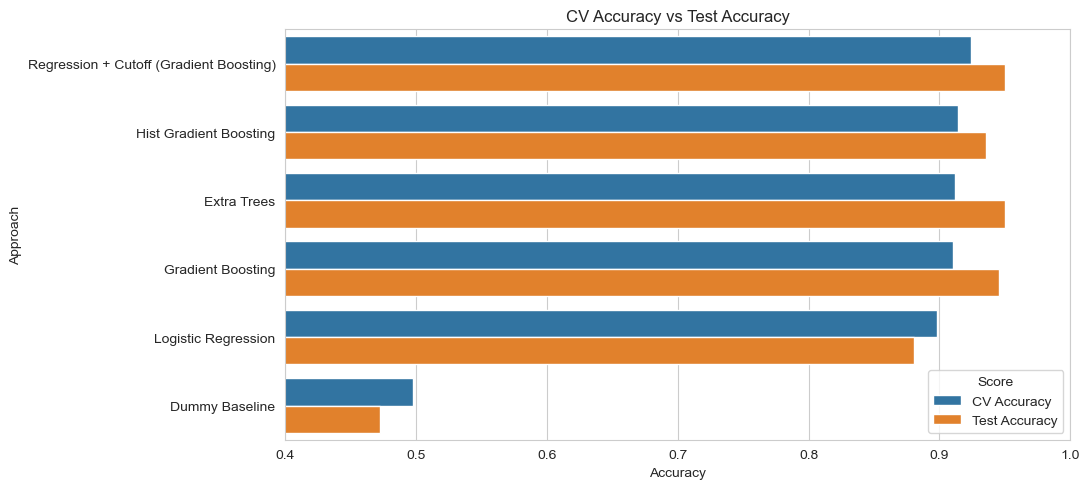

In [38]:
plt.figure(figsize=(11, 5))

plot_data = class_table.melt(id_vars="Approach", value_vars=["CV Accuracy", "Test Accuracy"],
                             var_name="Score", value_name="Accuracy")
sns.barplot(data=plot_data, y="Approach", x="Accuracy", hue="Score")

plt.xlim(0.4, 1.0)
plt.title("CV Accuracy vs Test Accuracy")
plt.tight_layout()
plt.show()

In [48]:
# Best approach = highest CV accuracy (ignoring the dummy baseline)
real_models = class_table[class_table["Approach"] != "Dummy Baseline"]
best_class_name = real_models.iloc[0]["Approach"]

print(" Best classification approach:", best_class_name)

 Best classification approach: Regression + Cutoff (Gradient Boosting)


### 8.8 Final Test Evaluation
The test set is used here with the approach already chosen.

First a small helper that gives, for any data, the predicted class and a score (used for the ROC curve).

In [40]:
def predict_class(data):
    """Returns (predicted class, score) using the best classification approach."""
    if best_class_name == regression_approach_name:
        score = best_regressor.predict(data)             # predicted strength
        label = (score >= cutoff).astype(int)
    else:
        model = class_models[best_class_name]
        score = model.predict_proba(data)[:, 1]          # probability of Strong
        label = model.predict(data)
    return label, score

In [41]:
test_label, test_score = predict_class(X_test)

metrics = pd.DataFrame({
    "Score": [
        accuracy_score(y_test_c, test_label),
        precision_score(y_test_c, test_label),
        recall_score(y_test_c, test_label),
        f1_score(y_test_c, test_label),
        roc_auc_score(y_test_c, test_score),
    ]
}, index=["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"])

metrics.round(4)

,Score
Accuracy,0.9502
Precision,0.9444
Recall,0.9623
F1-Score,0.9533
ROC-AUC,0.9880


- **Accuracy:** how many predictions were correct.
- **Precision:** of the mixes we called Strong, how many really were.
- **Recall:** of the really Strong mixes, how many we found.

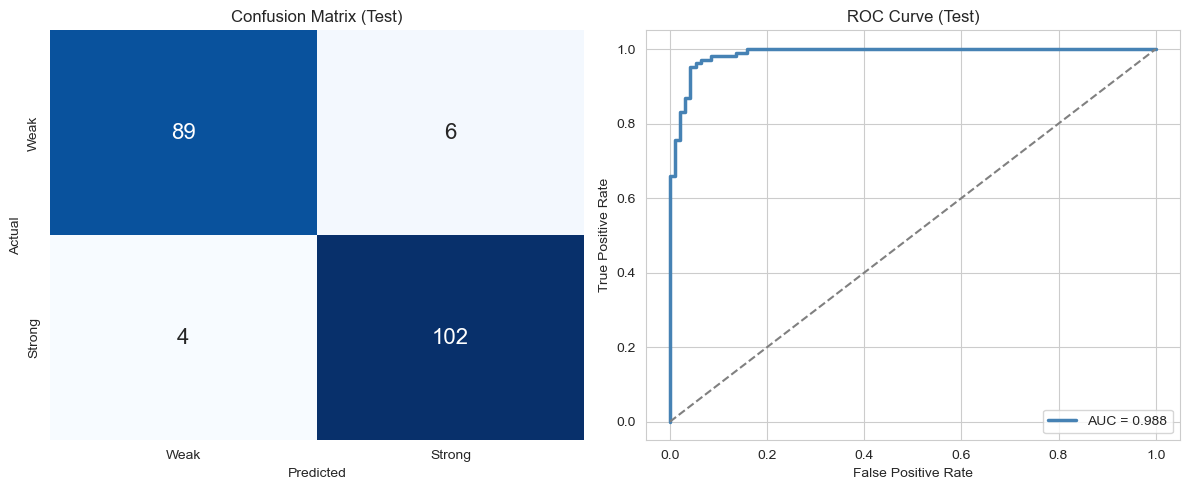

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion matrix
matrix = confusion_matrix(y_test_c, test_label)
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, annot_kws={"size": 16},
            xticklabels=["Weak", "Strong"], yticklabels=["Weak", "Strong"], ax=axes[0])
axes[0].set_title("Confusion Matrix (Test)")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# ROC curve
fpr, tpr, _ = roc_curve(y_test_c, test_score)
axes[1].plot(fpr, tpr, color="steelblue", linewidth=2.5, label=f"AUC = {roc_auc_score(y_test_c, test_score):.3f}")
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--")
axes[1].set_title("ROC Curve (Test)")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

### 8.9 Overfitting Check
If **Train** accuracy is much higher than **CV / Test**, the model is memorizing instead of learning.

                  Accuracy
Train (seen)         0.970
Cross-Validation     0.924
Test (unseen)        0.950


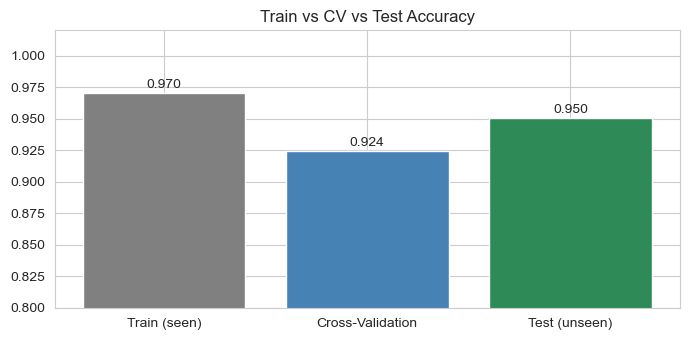

In [43]:
train_label, _ = predict_class(X_train)
best_row = class_table[class_table["Approach"] == best_class_name].iloc[0]

overfit_table = pd.DataFrame({
    "Accuracy": [
        accuracy_score(y_train_c, train_label),
        best_row["CV Accuracy"],
        accuracy_score(y_test_c, test_label)
    ]
}, index=["Train (seen)", "Cross-Validation", "Test (unseen)"])

print(overfit_table.round(3))

plt.figure(figsize=(7, 3.5))
bars = plt.bar(overfit_table.index, overfit_table["Accuracy"], color=["gray", "steelblue", "seagreen"])
plt.bar_label(bars, fmt="%.3f", padding=2)
plt.ylim(0.8, 1.02)
plt.title("Train vs CV vs Test Accuracy")
plt.tight_layout()
plt.show()

## 9. Save the Model & Predict a New Mix
We retrain the chosen models on **all** the data (train + test) so they learn from as many examples as possible, then save everything in one file.

> The scores above come from models trained on the training set only, so they are honest.

In [44]:
# Retrain the regression model on all data
final_regressor = clone(best_regressor)
final_regressor.fit(X, y)

# Retrain the classifier on all data (only needed if a direct classifier won)
if best_class_name == regression_approach_name:
    final_classifier = None
else:
    final_classifier = clone(class_models[best_class_name])
    final_classifier.fit(X, (y >= cutoff).astype(int))

# Save everything in one file
bundle = {
    "regressor": final_regressor,
    "classifier": final_classifier,
    "cutoff": cutoff
}
joblib.dump(bundle, "concrete_model.pkl")
print("Saved as 'concrete_model.pkl'")

Saved as 'concrete_model.pkl'


### Try it: predict a new concrete mix
You only need the 8 original values. The new features are added automatically.

In [45]:
def predict_mix(raw_mix):
    """Takes a dictionary with the 8 raw values and returns (strength, label)."""
    bundle = joblib.load("concrete_model.pkl")

    mix = add_features(pd.DataFrame([raw_mix]))
    strength = bundle["regressor"].predict(mix)[0]

    if bundle["classifier"] is None:
        is_strong = strength >= bundle["cutoff"]
    else:
        is_strong = bundle["classifier"].predict(mix)[0] == 1

    return strength, ("STRONG" if is_strong else "WEAK")


new_mix = {
    "Cement": 380,
    "Blast_Furnace_Slag": 95,
    "Fly_Ash": 0,
    "Water": 175,
    "Superplasticizer": 6,
    "Coarse_Aggregate": 975,
    "Fine_Aggregate": 825,
    "Age": 28
}

strength, label = predict_mix(new_mix)
print(f"Predicted strength: {strength:.1f} MPa  ->  {label}  (cutoff = {cutoff:.1f} MPa)")

Predicted strength: 54.6 MPa  ->  STRONG  (cutoff = 33.7 MPa)


## 10. Final Summary

In [46]:
best_reg = reg_table.iloc[0]

print("PART 1 — REGRESSION")
print(f"  Best model : {best_reg['Model']}")
print(f"  CV R2      : {best_reg['CV R2']:.3f}")
print(f"  Test R2    : {best_reg['Test R2']:.3f}")
print(f"  Test RMSE  : {best_reg['Test RMSE (MPa)']:.2f} MPa")
print(f"  Test MAE   : {best_reg['Test MAE (MPa)']:.2f} MPa")
print(f"  Top features: {', '.join(top_features)}")

print()
print("PART 2 — CLASSIFICATION (Strong vs Weak)")
print(f"  Best approach : {best_class_name}")
print(f"  CV Accuracy   : {best_row['CV Accuracy']:.3f}")
print(f"  Test Accuracy : {accuracy_score(y_test_c, test_label):.3f}")
print(f"  Test F1       : {f1_score(y_test_c, test_label):.3f}")
print(f"  Test ROC-AUC  : {roc_auc_score(y_test_c, test_score):.3f}")

PART 1 — REGRESSION
  Best model : Gradient Boosting
  CV R2      : 0.927
  Test R2    : 0.951
  Test RMSE  : 3.76 MPa
  Test MAE   : 2.57 MPa
  Top features: Water_Binder_Ratio, Log_Age, Age

PART 2 — CLASSIFICATION (Strong vs Weak)
  Best approach : Regression + Cutoff (Gradient Boosting)
  CV Accuracy   : 0.924
  Test Accuracy : 0.950
  Test F1       : 0.953
  Test ROC-AUC  : 0.988


### How to read the results
- **R²** close to 1 means the model explains most of the variation in strength. **RMSE / MAE** tell you the typical error in MPa.
- Trust the **CV score** more than a single test score: the test set is small, so its score can be a bit higher or lower by chance.
- Mixes whose strength is very close to the cutoff are naturally hard to classify.
- The Strong / Weak label is a **median split chosen for this project**, not an engineering standard.
- Feature importance shows what the model uses, **not** proof of cause and effect.